# 04 Weekly cohort retention heatmap

Source: `results/04_cohort_retention.csv` (from `04_cohort_retention.sql`).
Cohort = week of the user's first event (Monday weeks); retained = any event in week N.

- The **2020-10-26** cohort is excluded: it covers one day (Nov 1) and is left-censored.
- Week 0 is 100% by definition, so it is drawn in gray and kept off the color scale.
  Otherwise it would wash out the 0-7% range where the real differences are.

In [1]:
import pandas as pd
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

from pathlib import Path

# The project root is one level up from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

def results_path(name):
    return ROOT / "results" / name


In [2]:
import matplotlib.pyplot as plt

INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
})


In [3]:
df = pd.read_csv(results_path("04_cohort_retention.csv"), parse_dates=["cohort_week"])
df = df[df["cohort_week"] != "2020-10-26"]

rate = df.pivot(index="cohort_week", columns="week_number", values="retention_rate")
sizes = df.groupby("cohort_week")["cohort_users"].first()
rate.shape

(13, 13)

saved 04_cohort_heatmap.png


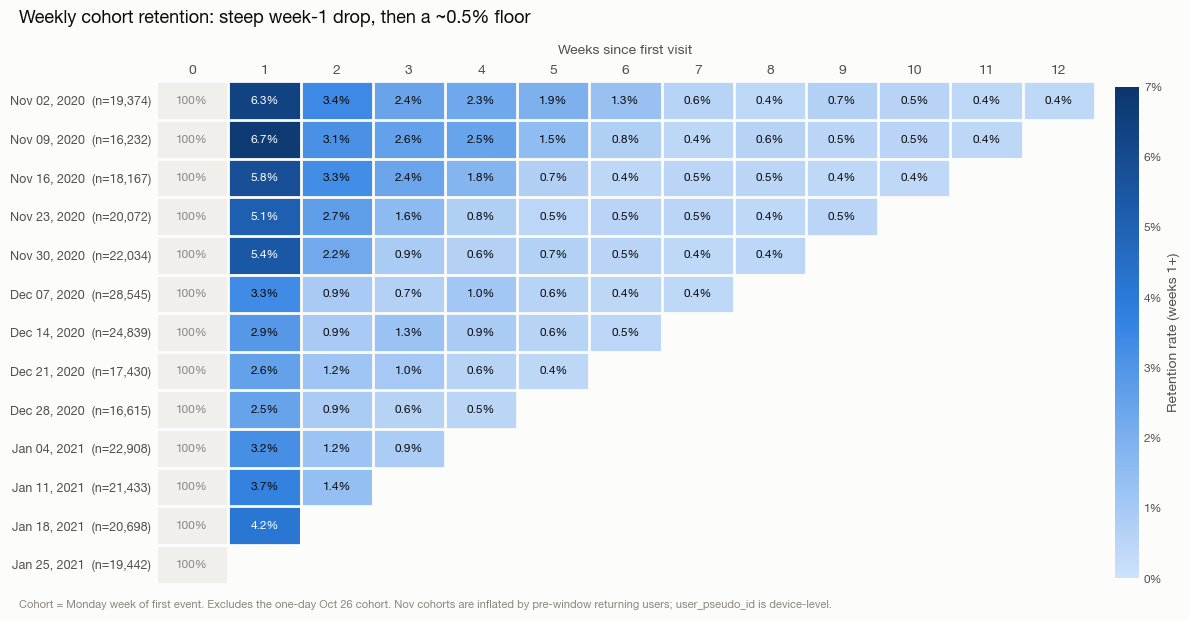

In [4]:
# Sequential single-hue blue ramp (light = low retention, dark = high).
BLUES = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
         "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
cmap = LinearSegmentedColormap.from_list("seq_blue", BLUES)
cmap.set_bad(SURFACE)  # cells with no data yet (right-censored) stay blank

later = rate.drop(columns=0)
vmax = np.ceil(later.max().max() * 100) / 100   # round up to the next whole %

fig, ax = plt.subplots(figsize=(12, 6.2))
img = ax.imshow(later.to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect="auto",
                extent=(0.5, later.shape[1] + 0.5, len(rate) - 0.5, -0.5))

# Week 0 column: neutral gray, outside the color scale.
for i in range(len(rate)):
    ax.add_patch(plt.Rectangle((-0.5, i - 0.5), 1, 1, color="#f0efec"))
    ax.text(0, i, "100%", ha="center", va="center", fontsize=8.5, color=MUTED)

# White gridlines between cells.
for x in np.arange(-0.5, rate.shape[1]):
    ax.axvline(x, color=SURFACE, lw=2)
for y in np.arange(-0.5, len(rate)):
    ax.axhline(y, color=SURFACE, lw=2)

# Percent labels; light text on dark cells.
for i, cohort in enumerate(rate.index):
    for j in later.columns:
        v = later.at[cohort, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if v / vmax > 0.55 else INK)

ax.set_xlim(-0.5, rate.shape[1] - 0.5)
ax.set_ylim(len(rate) - 0.5, -0.5)
ax.set_xticks(range(rate.shape[1]))
ax.set_xticklabels(rate.columns)
ax.set_yticks(range(len(rate)))
ax.set_yticklabels([f"{d:%b %d, %Y}  (n={sizes[d]:,})" for d in rate.index], fontsize=9)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Weeks since first visit", labelpad=8)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)

cbar = fig.colorbar(img, ax=ax, fraction=0.025, pad=0.02)
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
cbar.outline.set_visible(False)
cbar.ax.tick_params(length=0, labelsize=8.5)
cbar.set_label("Retention rate (weeks 1+)", color=INK_2)

fig.suptitle("Weekly cohort retention: steep week-1 drop, then a ~0.5% floor",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.015,
         "Cohort = Monday week of first event. Excludes the one-day Oct 26 cohort. "
         "Nov cohorts are inflated by pre-window returning users; user_pseudo_id is device-level.",
         fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))

out = results_path("04_cohort_heatmap.png")
fig.savefig(out, dpi=200, facecolor=SURFACE)
print("saved", out.name)